Epoch 0: Loss = 26.241348266601562
Epoch 500: Loss = 0.019575336948037148
Epoch 1000: Loss = 0.12299694120883942
Epoch 1500: Loss = 0.7863767147064209
Epoch 2000: Loss = 0.12336838990449905
Epoch 2500: Loss = 1.0114655494689941
Epoch 0: Loss = 0.8246939182281494
Epoch 500: Loss = 0.7503181099891663
Epoch 1000: Loss = 2.0166172981262207
Epoch 1500: Loss = 0.08195018768310547
Epoch 2000: Loss = 1.8566111326217651
Epoch 2500: Loss = 0.004766266327351332
Epoch 0: Loss = 0.004660886246711016
Epoch 500: Loss = 0.0007735075778327882
Epoch 1000: Loss = 1.1310807466506958
Epoch 1500: Loss = 0.7479167580604553
Epoch 2000: Loss = 1.4036723375320435
Epoch 2500: Loss = 0.15943828225135803
Epoch 0: Loss = 5.845058917999268
Epoch 500: Loss = 0.0072047957219183445
Epoch 1000: Loss = 5.918346881866455
Epoch 1500: Loss = 0.010264395736157894
Epoch 2000: Loss = 0.009762229397892952
Epoch 2500: Loss = 0.005232870113104582
Epoch 0: Loss = 2.1258838176727295
Epoch 500: Loss = 0.35786300897598267
Epoch 1000:

Epoch 2000: Loss = 0.21991078555583954
Epoch 2500: Loss = 1.668243408203125
Epoch 0: Loss = 0.6015294194221497
Epoch 500: Loss = 0.9803148508071899
Epoch 1000: Loss = 0.30444931983947754
Epoch 1500: Loss = 4.969870090484619
Epoch 2000: Loss = 27.256418228149414
Epoch 2500: Loss = 2.605877637863159
Epoch 0: Loss = 38.85993957519531
Epoch 500: Loss = 4.8793253898620605
Epoch 1000: Loss = 0.5440120100975037
Epoch 1500: Loss = 2.098482847213745
Epoch 2000: Loss = 0.036694787442684174
Epoch 2500: Loss = 9.097883224487305
Epoch 0: Loss = 26.386350631713867
Epoch 500: Loss = 9.664690017700195
Epoch 1000: Loss = 0.8060148358345032
Epoch 1500: Loss = 0.630915641784668
Epoch 2000: Loss = 1.175865888595581
Epoch 2500: Loss = 4.253701686859131


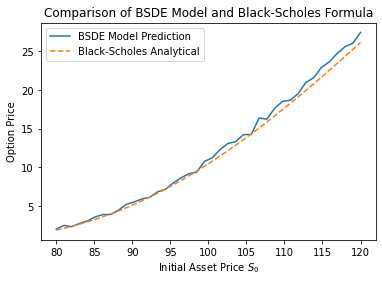

In [61]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Black-Scholes formula for European call option
def black_scholes_call(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return call_price

# Parameters for the European call option
T = 1.0    # Maturity
r = 0.05   # Risk-free rate
sigma = 0.2  # Volatility
K = 100    # Strike price
dim = 1    # Dimensionality (for a single asset)
N = 100    # Number of time steps
dt = T / N # Time step size

# Define the payoff for the European call option
def payoff(S):
    return tf.maximum(S - K, 0)

# Define the forward SDE to model the dynamics of the underlying asset for a European call option
@tf.function
def draw_X_and_dW(num_sample, S0, sigma, r, dt, N):
    dim = S0.shape[0]
    dW = tf.random.normal(shape=(num_sample, dim, N), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
    X = tf.ones((num_sample, dim, N + 1), dtype=DTYPE) * S0  # Initialize X with S0

    for i in range(N):
        X_t = X[:, :, i]  # Current value of X at time step i
        #X_next = X_t * tf.exp((r - 0.5 * sigma**2) * dt + sigma * dW[:, :, i])  # Compute next X_t
        X_next = X_t (r * dt + sigma * dW[:, :, i])  # Compute next X_t
        X = tf.concat([X[:, :, :i+1], tf.expand_dims(X_next, axis=-1), X[:, :, i+2:]], axis=-1)  # Update X

    return X, dW

# Define the neural network model for solving the BSDE
class BSDEModel(tf.keras.Model):
    def __init__(self, dim, N):
        super().__init__()
        self.u0 = tf.Variable(np.random.uniform(.1, .3, size=(1)).astype(DTYPE))
        self.gradu0 = tf.Variable(np.random.uniform(-1e-1, 1e-1, size=(1, dim)).astype(DTYPE))
        self.gradui = []
        for _ in range(N - 1):
            grad_network = tf.keras.Sequential()
            grad_network.add(tf.keras.layers.InputLayer(input_shape=(dim,)))
            grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            for _ in range(2):
                grad_network.add(tf.keras.layers.Dense(dim + 10, activation='relu', use_bias=False))
                grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            grad_network.add(tf.keras.layers.Dense(dim, use_bias=False))
            grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            self.gradui.append(grad_network)

    @tf.function
    def call(self, inputs):
        return self.u0 + tf.reduce_sum(self.gradu0 * inputs, axis=1, keepdims=True)

# Initialize model and optimizer
model = BSDEModel(dim, N)
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

# Loss function for BSDE
@tf.function
def loss_fn(u_pred, payoff):
    return tf.reduce_mean(tf.square(u_pred - payoff))

# Function to train the model and return predictions
@tf.function
def train_step(S0, batch_size):
    S0 = tf.cast(S0, DTYPE)  # Ensure S0 is float32
    with tf.GradientTape() as tape:
        # Simulate paths and Brownian increments for each batch
        X, dW = draw_X_and_dW(batch_size, tf.ones((dim,), dtype=DTYPE) * S0, sigma, r, dt, N)
        
        # Final time step payoff (call option)
        payoff_T = payoff(X[:, :, -1])  # Payoff at maturity

        # Predict the option price using the model at t=0
        u_pred = model(tf.convert_to_tensor(tf.ones((batch_size, dim), dtype=DTYPE) * S0, dtype=DTYPE))

        # Compute loss (MSE between predicted price and expected payoff)
        loss = loss_fn(u_pred, tf.reduce_mean(payoff_T))

    # Perform backpropagation and update the model
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    return loss

# Function to train and predict
def train_and_predict(S0, epochs=3000, batch_size=64):
    loss_history = []
    for epoch in range(epochs):
        loss = train_step(S0, batch_size)
        loss_history.append(loss.numpy())
        if epoch % 500 == 0:
            print(f"Epoch {epoch}: Loss = {loss.numpy()}")

    # Final prediction for the option price
    u0_pred = model(tf.convert_to_tensor([[S0]], dtype=DTYPE)).numpy()[0][0]
    return u0_pred, loss_history

# Run the model with different initial stock prices (S0)
S0_values = np.linspace(80, 120, 40)  # Test for different initial asset prices
model_predictions = []
bs_prices = []

for S0 in S0_values:
    u0_pred, _ = train_and_predict(S0)
    model_predictions.append(u0_pred)
    bs_price = black_scholes_call(S0, K, T, r, sigma)
    bs_prices.append(bs_price)

# Plot model predictions vs. Black-Scholes analytical solution
plt.plot(S0_values, model_predictions, label='BSDE Model Prediction')
plt.plot(S0_values, bs_prices, label='Black-Scholes Analytical', linestyle='--')
plt.xlabel('Initial Asset Price $S_0$')
plt.ylabel('Option Price')
plt.title('Comparison of BSDE Model and Black-Scholes Formula')
plt.savefig('DeepBSDE_BSM.png', format='png')
plt.legend()
plt.show()


Epoch 0: Loss = 47.33423614501953
Epoch 500: Loss = 0.0724710002541542
Epoch 1000: Loss = 0.1701948195695877
Epoch 1500: Loss = 0.35477516055107117
Epoch 2000: Loss = 0.08364123106002808
Epoch 2500: Loss = 0.399453341960907
Epoch 0: Loss = 0.8678618669509888
Epoch 500: Loss = 0.17710110545158386
Epoch 1000: Loss = 1.0813919305801392
Epoch 1500: Loss = 0.00328108761459589
Epoch 2000: Loss = 0.8137884140014648
Epoch 2500: Loss = 0.054251529276371
Epoch 0: Loss = 1.0249229669570923
Epoch 500: Loss = 0.2014118880033493
Epoch 1000: Loss = 0.37591302394866943
Epoch 1500: Loss = 0.17719794809818268
Epoch 2000: Loss = 1.1274075508117676
Epoch 2500: Loss = 0.14306387305259705
Epoch 0: Loss = 3.183664321899414
Epoch 500: Loss = 0.00439460389316082
Epoch 1000: Loss = 3.5290281772613525
Epoch 1500: Loss = 0.02133937180042267
Epoch 2000: Loss = 0.016025997698307037
Epoch 2500: Loss = 0.0002728639228735119
Epoch 0: Loss = 1.0454165935516357
Epoch 500: Loss = 0.5382314324378967
Epoch 1000: Loss = 0.7

Epoch 2000: Loss = 2.9179553985595703
Epoch 2500: Loss = 0.6725090146064758
Epoch 0: Loss = 0.03274848312139511
Epoch 500: Loss = 2.08292293548584
Epoch 1000: Loss = 0.34723421931266785
Epoch 1500: Loss = 1.5745537281036377
Epoch 2000: Loss = 21.87299156188965
Epoch 2500: Loss = 0.9660786390304565
Epoch 0: Loss = 43.55728530883789
Epoch 500: Loss = 4.985751628875732
Epoch 1000: Loss = 0.10937631130218506
Epoch 1500: Loss = 2.0068182945251465
Epoch 2000: Loss = 0.9836716055870056
Epoch 2500: Loss = 6.136026382446289
Epoch 0: Loss = 25.008678436279297
Epoch 500: Loss = 10.919635772705078
Epoch 1000: Loss = 0.016167987138032913
Epoch 1500: Loss = 0.8656138181686401
Epoch 2000: Loss = 0.7511410713195801
Epoch 2500: Loss = 4.385170936584473


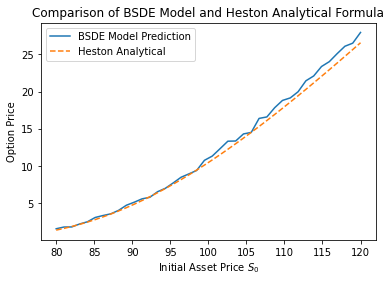

In [62]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad
from numpy import exp, sqrt, log, pi

# Set data type
DTYPE = 'float32'
tf.keras.backend.set_floatx(DTYPE)

# Parameters for the Heston model
T = 1.0    # Maturity
r = 0.05   # Risk-free rate
kappa = 2.0  # Mean reversion speed
theta = 0.04  # Long-term variance
sigma_v = 0.2  # Volatility of volatility
rho = -0.7    # Correlation between the two Brownian motions
v0 = 0.04     # Initial variance
K = 100    # Strike price
dim = 1    # Dimensionality (for a single asset)
N = 100    # Number of time steps
dt = T / N # Time step size

# Define the payoff for the European call option
def payoff(S):
    return tf.maximum(S - K, 0)

# Define the forward SDE for the Heston model
@tf.function
def draw_X_and_dW(num_sample, S0, v0, sigma_v, r, dt, N, kappa, theta, rho):
    dim = S0.shape[0]
    dW1 = tf.random.normal(shape=(num_sample, dim, N), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
    dW2 = rho * dW1 + tf.sqrt(1 - rho**2) * tf.random.normal(shape=(num_sample, dim, N), mean=0.0, stddev=tf.sqrt(dt), dtype=DTYPE)
    
    # Initialize S and v with initial values
    S = tf.ones((num_sample, dim, N + 1), dtype=DTYPE) * S0
    v = tf.ones((num_sample, dim, N + 1), dtype=DTYPE) * v0

    for i in range(N):
        S_t = S[:, :, i]  # Current value of S at time step i
        v_t = v[:, :, i]  # Current value of v at time step i
        
        # Compute next v_t (variance process)
        v_next = tf.maximum(v_t + kappa * (theta - v_t) * dt + sigma_v * tf.sqrt(v_t) * dW2[:, :, i], 0)
        v = tf.concat([v[:, :, :i+1], tf.expand_dims(v_next, axis=-1), v[:, :, i+2:]], axis=-1)  # Update v
        
        # Compute next S_t (asset price process)
        S_next = S_t * tf.exp((r - 0.5 * v_t) * dt + tf.sqrt(v_t) * dW1[:, :, i])
        S = tf.concat([S[:, :, :i+1], tf.expand_dims(S_next, axis=-1), S[:, :, i+2:]], axis=-1)  # Update S

    return S, v, dW1, dW2

# Define the neural network model for solving the BSDE
class BSDEModel(tf.keras.Model):
    def __init__(self, dim, N):
        super().__init__()
        self.u0 = tf.Variable(np.random.uniform(.1, .3, size=(1)).astype(DTYPE))
        self.gradu0 = tf.Variable(np.random.uniform(-1e-1, 1e-1, size=(1, dim)).astype(DTYPE))
        self.gradui = []
        for _ in range(N - 1):
            grad_network = tf.keras.Sequential()
            grad_network.add(tf.keras.layers.InputLayer(input_shape=(dim,)))
            grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            for _ in range(2):
                grad_network.add(tf.keras.layers.Dense(dim + 10, activation='relu', use_bias=False))
                grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            grad_network.add(tf.keras.layers.Dense(dim, use_bias=False))
            grad_network.add(tf.keras.layers.BatchNormalization(momentum=0.99, epsilon=1e-6))
            self.gradui.append(grad_network)

    @tf.function
    def call(self, inputs):
        return self.u0 + tf.reduce_sum(self.gradu0 * inputs, axis=1, keepdims=True)

# Initialize model and optimizer
model = BSDEModel(dim, N)
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

# Loss function for BSDE
@tf.function
def loss_fn(u_pred, payoff):
    return tf.reduce_mean(tf.square(u_pred - payoff))

# Function to train the model and return predictions
@tf.function
def train_step(S0, v0, batch_size):
    S0 = tf.cast(S0, DTYPE)  # Ensure S0 is float32
    v0 = tf.cast(v0, DTYPE)  # Ensure v0 is float32
    with tf.GradientTape() as tape:
        # Simulate paths and Brownian increments for each batch
        S, v, dW1, dW2 = draw_X_and_dW(batch_size, tf.ones((dim,), dtype=DTYPE) * S0, v0, sigma_v, r, dt, N, kappa, theta, rho)
        
        # Final time step payoff (call option)
        payoff_T = payoff(S[:, :, -1])  # Payoff at maturity

        # Predict the option price using the model at t=0
        u_pred = model(tf.convert_to_tensor(tf.ones((batch_size, dim), dtype=DTYPE) * S0, dtype=DTYPE))

        # Compute loss (MSE between predicted price and expected payoff)
        loss = loss_fn(u_pred, tf.reduce_mean(payoff_T))

    # Perform backpropagation and update the model
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    return loss

# Function to train and predict
def train_and_predict(S0, v0, epochs=3000, batch_size=64):
    loss_history = []
    for epoch in range(epochs):
        loss = train_step(S0, v0, batch_size)
        loss_history.append(loss.numpy())
        if epoch % 500 == 0:
            print(f"Epoch {epoch}: Loss = {loss.numpy()}")

    # Final prediction for the option price
    u0_pred = model(tf.convert_to_tensor([[S0]], dtype=DTYPE)).numpy()[0][0]
    return u0_pred, loss_history


# Public function to calculate call price
def call_price(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K):
    p1 = __p1(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K)
    p2 = __p2(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K)
    return (s0 * p1 - K * exp(-r * T) * p2)

# Private helper functions
def __p(kappa, theta, sigma, rho, v0 ,r ,T ,s0 , K, status):
    integrand = lambda phi: (exp(-1j * phi * log(K)) * 
    __f(phi, kappa, theta, sigma, rho, v0, r, T, s0, status) / (1j * phi)).real    
    return (0.5 + (1 / pi) * quad(integrand, 0, 100)[0])

def __p1(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K):
    return __p(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K, 1)

def __p2(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K):
    return __p(kappa, theta, sigma, rho, v0 ,r ,T ,s0 ,K, 2)

def __f(phi, kappa, theta, sigma, rho, v0, r, T, s0, status):
        
    if status == 1:
        u = 0.5
        b = kappa - rho * sigma
    else:
        u = -0.5
        b = kappa
    
    a = kappa * theta
    x = log(s0)
    d = sqrt((rho * sigma * phi * 1j - b)**2 - sigma**2 * (2 * u * phi * 1j - phi**2))
    g = (b - rho * sigma * phi * 1j + d) / (b - rho * sigma * phi * 1j - d)
    C = r * phi * 1j * T + (a / sigma**2)*((b - rho * sigma * phi * 1j + d) * T - 2 * log((1 - g * exp(d * T))/(1 - g)))
    D = (b - rho * sigma * phi * 1j + d) / sigma**2 * ((1 - exp(d * T)) / (1 - g * exp(d * T)))
    return exp(C + D * v0 + 1j * phi * x)

# Run the model with different initial stock prices (S0)
S0_values = np.linspace(80, 120, 40)  # Test for different initial asset prices
v0_value = v0  # Initial variance
model_predictions = []
heston_prices = []

for S0 in S0_values:
    # DeepBSDE model prediction
    u0_pred, _ = train_and_predict(S0, v0_value)
    model_predictions.append(u0_pred)

    # Heston analytical price
    heston_price = call_price(kappa, theta, sigma_v, rho, v0_value, r, T, S0, K)
    heston_prices.append(heston_price)

# Plot model predictions vs. Heston analytical solution
plt.plot(S0_values, model_predictions, label='BSDE Model Prediction')
plt.plot(S0_values, heston_prices, label='Heston Analytical', linestyle='--')
plt.xlabel('Initial Asset Price $S_0$')
plt.ylabel('Option Price')
plt.title('Comparison of BSDE Model and Heston Analytical Formula')
plt.savefig('DeepBSDE_heston.png', format='png')
plt.legend()
plt.show()


